## DECOM: INTELIGENCIA COMPUTACIONAL, Prof. Rogério; Autor: Marco Túlio S. da Mata; CEFET-MG

# Simulated Annealing para Posicionamento de Células em Projetos VLSI

Exploraremos o algoritmo de **Recozimento Simulado (Simulated Annealing - SA)**
para resolver o problema de **posicionamento de células (cell placement)**, uma das etapas mais
importantes da fase de **Place and Route (P&R)** no fluxo de projeto físico de circuitos
integrados (VLSI).

Os dados de entrada são carregados de dois arquivos `.csv`:

- `componentes.csv` — lista das células do circuito (`Componente;Largura;Altura`).
- `netlist.csv` — conectividade do circuito (`Net;Componente`), isto é, quais células pertencem a
  cada rede (net) elétrica.

Veja a lógica do algoritmo que está implementada no módulo `sa_vlsi_placement.py`.

## 1. Contexto: Place and Route em projetos VLSI

O fluxo de projeto físico (*physical design*) de um circuito integrado converte uma descrição
lógica do circuito (netlist, gerada pela síntese lógica) em um layout físico pronto para
fabricação. As duas etapas centrais desse fluxo são:

- **Placement (posicionamento)**: decidir *onde*, fisicamente, cada célula do circuito
  (portas lógicas, flip-flops, buffers, etc.) será posicionada na área do chip.
- **Routing (roteamento)**: decidir *como* os fios que conectam essas células (de acordo com a
  netlist) serão efetivamente traçados nas camadas de metal do chip, respeitando regras de
  fabricação e evitando conflitos entre fios.

O *placement* tem um impacto enorme sobre a qualidade do roteamento e sobre as métricas finais do
chip:

- Um posicionamento ruim aumenta o **comprimento total de fiação** (wirelength), o que aumenta a
  **área** ocupada pelas camadas de roteamento, o **atraso** de propagação dos sinais (delay) e o
  **consumo de energia** dinâmico (proporcional à capacitância das interconexões).
- Como o roteamento exato só pode ser calculado após o posicionamento estar (ao menos
  aproximadamente) definido, ferramentas de *placement* usam uma **estimativa de fiação** barata de
  calcular, o **HPWL (Half-Perimeter Wire Length)**, como *proxy* para o comprimento real que o
  roteador vai produzir depois. Minimizar o HPWL durante o *placement* tende a produzir circuitos
  com roteamento mais curto, mais rápido e mais eficiente energeticamente.

O SA é historicamente uma das técnicas mais usadas para *placement* de células-padrão
(*standard-cell placement*) em ferramentas acadêmicas e comerciais de EDA — o exemplo clássico é a
ferramenta **TimberWolf** (Sechen & Sangiovanni-Vincentelli, anos 1980), que popularizou o uso de
SA para esse problema e influenciou gerações de ferramentas posteriores.

## 2. Fundamentação teórica do Simulated Annealing

No processo metalúrgico de *annealing* (recozimento): um
material é aquecido a uma temperatura alta (o que dá energia suficiente aos átomos para se
rearranjarem livremente) e depois resfriado lentamente, permitindo que os átomos se acomodem em uma
configuração de baixa energia (uma estrutura cristalina mais estável) em vez de ficarem presos em
uma configuração desordenada.

Analogamente, no algoritmo:

- Uma **solução** é uma configuração do sistema — aqui, um posicionamento das células na grade.
- O **custo** de uma solução equivale à "energia" do sistema — aqui, o HPWL total da netlist.
- A cada iteração, uma solução vizinha é gerada por uma pequena perturbação (um **movimento**) —
  aqui, a troca de posição entre duas células (ou entre uma célula e um sítio vazio).
- O movimento é aceito imediatamente se reduz o custo. Se aumenta o custo em Δ, ele ainda pode ser
  aceito com probabilidade dada pelo **critério de Metropolis**:

$$
P(\text{aceitar}) = e^{-\Delta / T}
$$

  onde *T* é a temperatura atual. Assim, no início (T alta), o algoritmo aceita quase qualquer
  movimento, explorando amplamente o espaço de soluções e escapando de mínimos locais. Conforme *T*
  diminui (**cronograma de resfriamento** / *cooling schedule*), o algoritmo se torna cada vez mais
  seletivo, refinando a solução até convergir.

Neste módulo, o cronograma de resfriamento é **geométrico**:

$$
T_{k+1} = T_k \cdot r, \qquad 0 < r < 1
$$

onde *r* é a **taxa de resfriamento**. Em cada patamar de temperatura, um número fixo de
movimentos é tentado antes de resfriar (`iteracoes_por_temperatura`).


## 3. Carregamento dos dados

Vamos carregar `componentes.csv` (células do circuito) e `netlist.csv` (conectividade), e
construir a estrutura de redes usada pelo algoritmo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sa_vlsi_placement import (
    carregar_componentes,
    carregar_netlist,
    construir_redes,
    dimensoes_grade_sugerida,
    SAPlacement,
    plotar_posicionamento,
    plotar_convergencia,
    plotar_taxa_aceitacao,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 100


In [2]:
CAMINHO_COMPONENTES = "componentes.csv"
CAMINHO_NETLIST = "netlist.csv"

df_componentes = carregar_componentes(CAMINHO_COMPONENTES)
df_netlist = carregar_netlist(CAMINHO_NETLIST)

print(f"{len(df_componentes)} componentes carregados.")
df_componentes.head()


24 componentes carregados.


,Componente,Largura,Altura
0,C1,1.0,1.0
1,C2,1.0,1.0
2,C3,1.0,1.0
3,C4,1.0,1.0
4,C5,1.0,1.0


In [3]:
redes = construir_redes(df_componentes, df_netlist)
print(f"{len(redes)} redes (nets) construídas a partir da netlist.")

# distribuição do número de pinos por net (fan-out da net)
tam_redes = pd.Series({net: len(comps) for net, comps in redes.items()})
tam_redes.sort_values(ascending=False).head(10)


24 redes (nets) construídas a partir da netlist.


CLK    10
RST     6
N2      4
N11     3
N20     3
N19     3
N18     3
N15     3
N13     3
N5      3
dtype: int64

### Dimensionamento da grade de posicionamento

Sugerimos uma grade quadrada com uma pequena folga de sítios vazios em relação ao número de
componentes — isso é comum em posicionamento VLSI, tanto para deixar espaço para canais de
roteamento quanto para viabilizar os movimentos de troca do próprio algoritmo SA.

In [4]:
n_linhas, n_colunas = dimensoes_grade_sugerida(len(df_componentes), folga=1.25)
print(f"Grade sugerida: {n_linhas} linhas x {n_colunas} colunas "
      f"({n_linhas * n_colunas} sítios para {len(df_componentes)} componentes)")


Grade sugerida: 6 linhas x 5 colunas (30 sítios para 24 componentes)


## 4. Configuração e execução do algoritmo SA

Os principais hiperparâmetros do algoritmo são:

| Parâmetro | Descrição | Valor usado |
|---|---|---|
| `temperatura_inicial` | Temperatura inicial (deve aceitar quase todos os movimentos) | 500 |
| `temperatura_final` | Critério de parada (temperatura mínima) | 0.5 |
| `taxa_resfriamento` | Fator geométrico de resfriamento a cada patamar | 0.92 |
| `iteracoes_por_temperatura` | Movimentos tentados em cada patamar de temperatura | 150 |

Esses valores são um bom ponto de partida para circuitos pequenos/médios, mas devem ser calibrados
conforme o tamanho do circuito (número de células e de nets).

In [5]:
sa = SAPlacement(
    n_componentes=len(df_componentes),
    redes=redes,
    n_linhas=n_linhas,
    n_colunas=n_colunas,
    temperatura_inicial=500.0,
    temperatura_final=0.5,
    taxa_resfriamento=0.92,
    iteracoes_por_temperatura=150,
    semente=42,  # para resultados reprodutíveis
)

custo_inicial = sa.custo_atual
posicoes_iniciais = dict(sa.posicao_componente)
print(f"Custo (HPWL total) do posicionamento inicial aleatório: {custo_inicial:.1f}")

historico = sa.executar()

print(f"Melhor custo (HPWL total) encontrado: {historico.melhor_custo_global:.1f}")
reducao_pct = 100 * (1 - historico.melhor_custo_global / custo_inicial)
print(f"Redução em relação ao posicionamento inicial: {reducao_pct:.1f}%")


Custo (HPWL total) do posicionamento inicial aleatório: 109.0
Melhor custo (HPWL total) encontrado: 59.0
Redução em relação ao posicionamento inicial: 45.9%


## 5. Visualização dos resultados

### 5.1 Posicionamento inicial (aleatório) x posicionamento final (otimizado)

Cada célula é desenhada como um quadrado na grade, com as conexões de cada net desenhadas como
linhas ligando as células ao centróide da net (uma representação em "estrela", comum em
ferramentas de EDA para não poluir o desenho com todas as combinações par a par de pinos).

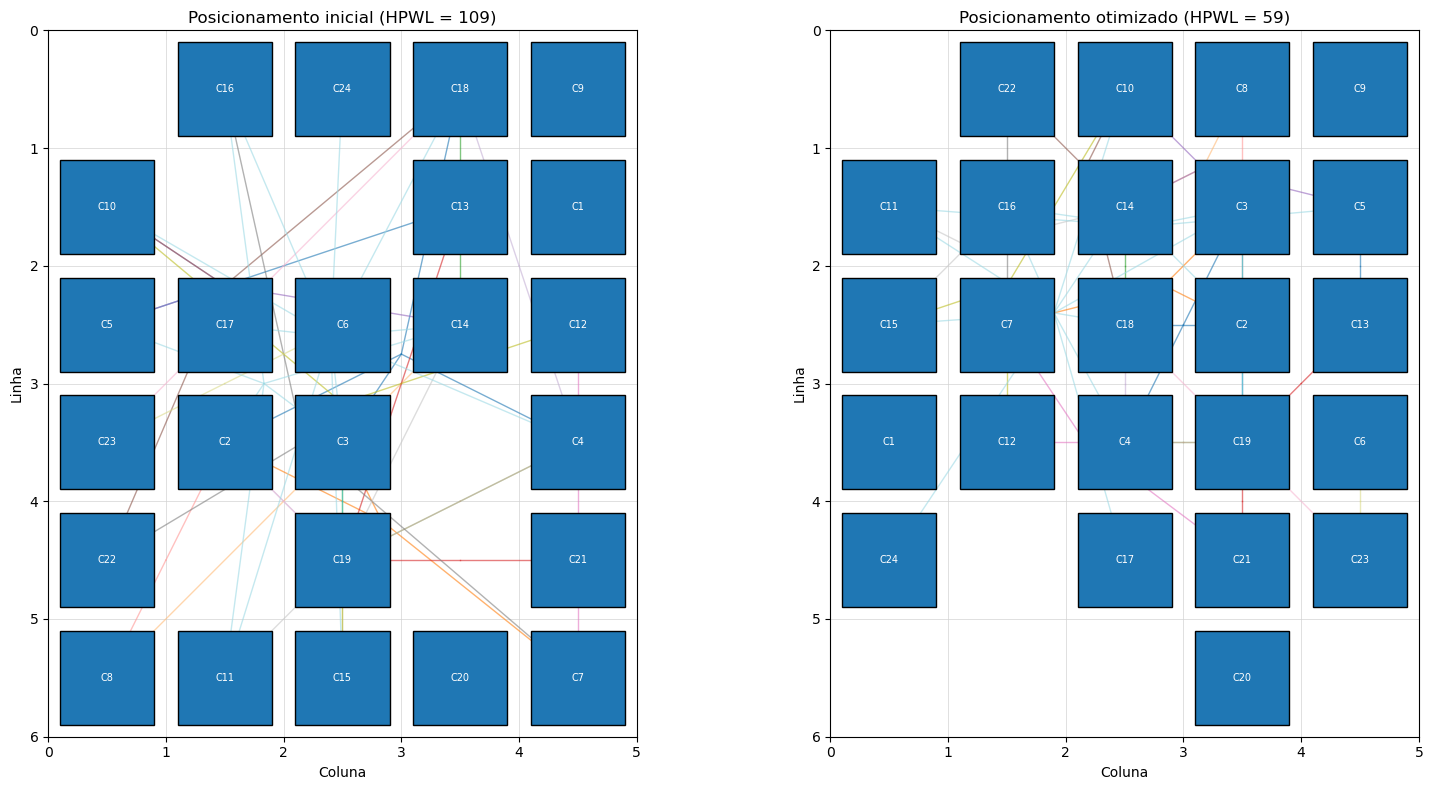

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

plotar_posicionamento(
    df_componentes, redes, posicoes_iniciais, n_linhas, n_colunas, ax=ax1,
    titulo=f"Posicionamento inicial (HPWL = {custo_inicial:.0f})"
)
plotar_posicionamento(
    df_componentes, redes, historico.melhor_posicoes_global, n_linhas, n_colunas, ax=ax2,
    titulo=f"Posicionamento otimizado (HPWL = {historico.melhor_custo_global:.0f})"
)

plt.tight_layout()
plt.show()


### 5.2 Curva de convergência

O gráfico abaixo mostra a evolução do custo (HPWL total) ao longo das iterações, junto com a
temperatura (eixo secundário, escala logarítmica), evidenciando como a solução se estabiliza
conforme o sistema esfria.

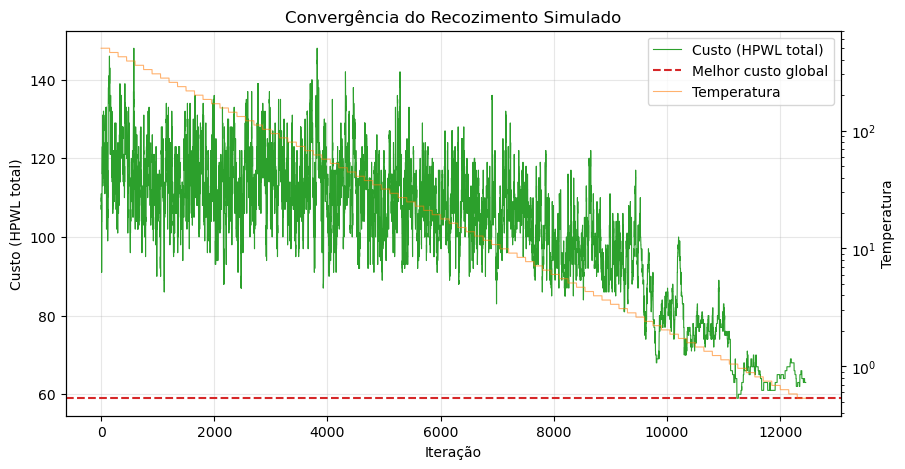

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
plotar_convergencia(historico, ax=ax)
plt.show()


### 5.3 Taxa de aceitação de movimentos

A taxa de aceitação de movimentos por patamar de temperatura é uma ferramenta clássica de
diagnóstico do cronograma de resfriamento: ela deve começar próxima de 1 (quase tudo é aceito) e
cair suavemente até próximo de 0 (quase nada é aceito) conforme o sistema esfria. Quedas bruscas
demais indicam resfriamento rápido, com risco de ficar preso em mínimos locais.

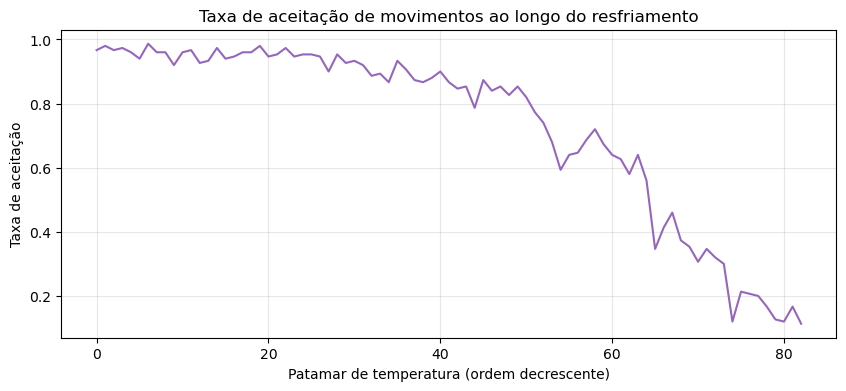

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
plotar_taxa_aceitacao(historico, ax=ax)
plt.show()


## 6. Experimentos: efeito do cronograma de resfriamento

O parâmetro mais sensível do SA costuma ser a **taxa de resfriamento**: valores muito baixos
(resfriamento rápido) tendem a convergir mais rápido, mas para soluções piores (ficam presos em
mínimos locais); valores muito próximos de 1 (resfriamento lento) exploram melhor o espaço de
busca, mas exigem muito mais iterações. Vamos comparar algumas opções.

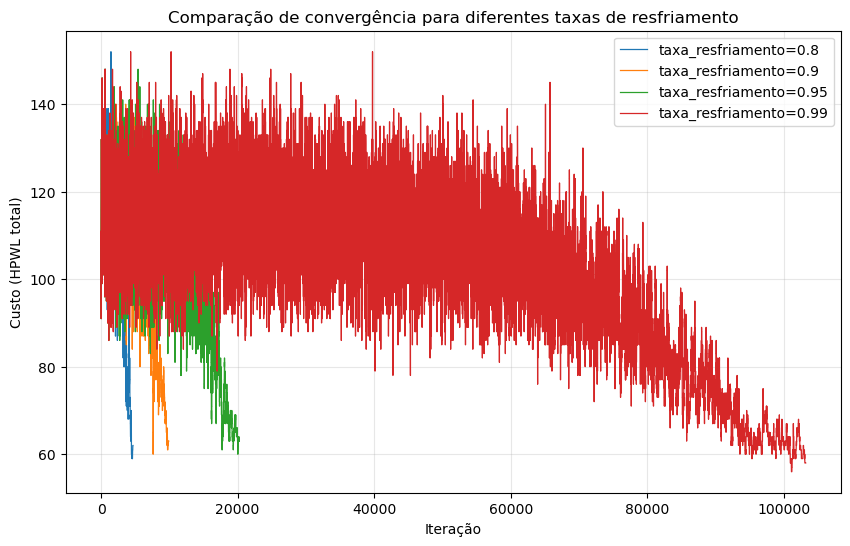

taxa_resfriamento=0.80 -> melhor HPWL: 59.0, total de iterações: 4650
taxa_resfriamento=0.90 -> melhor HPWL: 60.0, total de iterações: 9900
taxa_resfriamento=0.95 -> melhor HPWL: 60.0, total de iterações: 20250
taxa_resfriamento=0.99 -> melhor HPWL: 56.0, total de iterações: 103200


In [9]:
taxas_testadas = [0.80, 0.90, 0.95, 0.99]
resultados = {}

for taxa in taxas_testadas:
    sa_teste = SAPlacement(
        n_componentes=len(df_componentes),
        redes=redes,
        n_linhas=n_linhas,
        n_colunas=n_colunas,
        temperatura_inicial=500.0,
        temperatura_final=0.5,
        taxa_resfriamento=taxa,
        iteracoes_por_temperatura=150,
        semente=42,
    )
    hist_teste = sa_teste.executar()
    resultados[taxa] = hist_teste

fig, ax = plt.subplots(figsize=(10, 6))
for taxa, hist in resultados.items():
    ax.plot(hist.custo_por_iteracao, label=f"taxa_resfriamento={taxa}", linewidth=0.9)
ax.set_title("Comparação de convergência para diferentes taxas de resfriamento")
ax.set_xlabel("Iteração")
ax.set_ylabel("Custo (HPWL total)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

for taxa, hist in resultados.items():
    print(f"taxa_resfriamento={taxa:.2f} -> melhor HPWL: {hist.melhor_custo_global:.1f}, "
          f"total de iterações: {len(hist.custo_por_iteracao)}")


## 7. Conclusão

A implementação em `sa_vlsi_placement.py` resolve o problema de posicionamento
de células de forma heurística, reduzindo significativamente o HPWL total (estimativa de fiação)
em relação a um posicionamento inicial aleatório — refletindo diretamente na qualidade do
roteamento subsequente no fluxo de *Place and Route*.

Pontos de atenção ao aplicar o algoritmo em circuitos reais:

- **Escala do problema**: circuitos VLSI reais possuem milhares a milhões de células. Para esses
  casos, técnicas adicionais são necessárias, como *particionamento hierárquico* do circuito antes
  do SA, estruturas de dados mais eficientes para atualização incremental de custo, e paralelização
  dos movimentos.
- **Cronograma de resfriamento**: o equilíbrio entre `taxa_resfriamento` e
  `iteracoes_por_temperatura` é o principal fator que determina o compromisso entre tempo de
  execução e qualidade da solução final — assim como observado na literatura de ferramentas como o
  TimberWolf.
- **Métricas adicionais**: ferramentas de *placement* reais frequentemente combinam o HPWL com
  outras métricas no custo, como densidade de congestionamento de roteamento, atraso em caminhos
  críticos (timing) e restrições de área/legalização (alinhamento das células em linhas da grade,
  sem sobreposição de células de tamanhos diferentes).